# Grover con dos modelos de ruido — Tercera prueba

**Objetivo.** Comparar el algoritmo de Grover de **2 qubits** (solución `11`) en cuatro condiciones: **ideal**, **ruido despolarizante**, **error de lectura** y **ambos combinados**.

## 1. Preparar el entorno

- **Qiskit** construye el circuito; **Qiskit Aer** lo simula.
- **Matplotlib** representa las distribuciones de resultados.

In [1]:
from importlib.metadata import version
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

print("Qiskit:", version("qiskit"))
print("Qiskit Aer:", version("qiskit-aer"))

Qiskit: 2.6.0
Qiskit Aer: 0.17.2


## 2. Construir Grover (una iteración)

1. **H** en ambos qubits: prepara una superposición uniforme de `00`, `01`, `10` y `11`.
2. **CZ (oráculo):** marca `11` mediante un cambio de fase.
3. **H–X–CZ–X–H (difusor):** amplifica su amplitud.
4. **Medición:** registra el resultado al final. Sin ruido esperamos **100 % de `11`**.

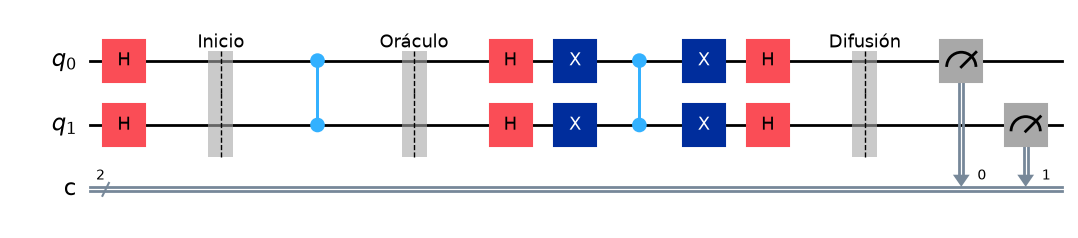

Operaciones: {'h': 6, 'x': 4, 'barrier': 3, 'cz': 2, 'measure': 2}


In [2]:
def crear_grover_2q():
    circuito = QuantumCircuit(2, 2)

    circuito.h([0, 1])
    circuito.barrier(label="Inicio")

    # Oráculo: marca |11>
    circuito.cz(0, 1)
    circuito.barrier(label="Oráculo")

    # Difusor (hasta una fase global)
    circuito.h([0, 1])
    circuito.x([0, 1])
    circuito.cz(0, 1)
    circuito.x([0, 1])
    circuito.h([0, 1])
    circuito.barrier(label="Difusión")

    circuito.measure([0, 1], [0, 1])
    return circuito

circuito = crear_grover_2q()
display(circuito.draw(output="mpl", style="iqp", fold=-1))
print("Operaciones:", dict(circuito.count_ops()))

## 3. Definir los modelos de ruido

**Despolarización (en las puertas):** introduce errores durante la evolución cuántica. Usamos parámetros **0,01** después de H y X, y **0,05** después de CZ. Para un canal de $n$ qubits:

$$\mathcal{E}(\rho)=(1-\lambda)\rho+\lambda\frac{I}{2^n}.$$

**Error de lectura (en las mediciones):** cada bit registrado se invierte con probabilidad **5 %**, independientemente del otro bit:

$$R=\begin{pmatrix}0.95&0.05\\0.05&0.95\end{pmatrix}.$$

El **modelo combinado** contiene ambos errores: los de puertas afectan al estado; los de lectura, a los bits observados. No se suman directamente sus porcentajes.

In [3]:
# Parámetros de la prueba
lambda_1q = 0.01
lambda_2q = 0.05
p_lectura = 0.05

error_1q = depolarizing_error(lambda_1q, 1)
error_2q = depolarizing_error(lambda_2q, 2)
error_lectura = ReadoutError([
    [1 - p_lectura, p_lectura],
    [p_lectura, 1 - p_lectura]
])

# Sólo errores de puertas
modelo_despolarizante = NoiseModel()
modelo_despolarizante.add_all_qubit_quantum_error(error_1q, ["h", "x"])
modelo_despolarizante.add_all_qubit_quantum_error(error_2q, ["cz"])

# Sólo errores de lectura
modelo_lectura = NoiseModel()
modelo_lectura.add_all_qubit_readout_error(error_lectura)

# Ambos modelos en la misma ejecución
modelo_combinado = NoiseModel()
modelo_combinado.add_all_qubit_quantum_error(error_1q, ["h", "x"])
modelo_combinado.add_all_qubit_quantum_error(error_2q, ["cz"])
modelo_combinado.add_all_qubit_readout_error(error_lectura)

print("Despolarización: H/X =", lambda_1q, "; CZ =", lambda_2q)
print("Lectura: error por qubit =", p_lectura)

Despolarización: H/X = 0.01 ; CZ = 0.05
Lectura: error por qubit = 0.05


## 4. Ejecutar las cuatro condiciones

Usamos el **mismo circuito**, el método `density_matrix` y **1024 shots** en todos los casos.

- **Iteraciones:** repeticiones del oráculo y difusor dentro del circuito; aquí solo hay una.
- **Shots:** muestras del resultado final; aquí obtenemos 1024 por condición.

La semilla fija permite reproducir las muestras. Comprobamos también que la transpilación no haya eliminado las puertas a las que asociamos ruido.

In [4]:
shots = 1024
semilla = 42

simuladores = {
    "Ideal": AerSimulator(method="density_matrix", seed_simulator=semilla),
    "Despolarizante": AerSimulator(
        method="density_matrix", noise_model=modelo_despolarizante,
        seed_simulator=semilla
    ),
    "Lectura": AerSimulator(
        method="density_matrix", noise_model=modelo_lectura,
        seed_simulator=semilla
    ),
    "Combinado": AerSimulator(
        method="density_matrix", noise_model=modelo_combinado,
        seed_simulator=semilla
    ),
}

# Compilación común para mantener constantes las operaciones
circuito_compilado = transpile(circuito, simuladores["Ideal"], optimization_level=0)
operaciones = dict(circuito_compilado.count_ops())
print("Operaciones tras transpilar:", operaciones)
if not all(operaciones.get(puerta, 0) > 0 for puerta in ("h", "x", "cz")):
    raise RuntimeError("Revisar la transpilación: no aparecen H, X y CZ, como exige el modelo.")

conteos = {
    nombre: simulador.run(circuito_compilado, shots=shots).result().get_counts()
    for nombre, simulador in simuladores.items()
}

for nombre, resultado in conteos.items():
    print(f"{nombre:15s}: {resultado}")
    assert sum(resultado.values()) == shots

Operaciones tras transpilar: {'h': 6, 'x': 4, 'barrier': 3, 'cz': 2, 'measure': 2}
Ideal          : {'11': 1024}
Despolarizante : {'11': 907, '01': 44, '10': 53, '00': 20}
Lectura        : {'11': 925, '10': 54, '01': 43, '00': 2}
Combinado      : {'11': 828, '00': 25, '10': 94, '01': 77}


## 5. Calcular la probabilidad de éxito

La solución es `11`. Estimamos la probabilidad observada como:

$$\widehat P_{\mathrm{éxito}}=\frac{\text{número de resultados `11`}}{\text{shots}}.$$

En el modelo de **solo lectura**, la probabilidad teórica de registrar correctamente `11` es $(1-0.05)^2=90.25\%$.

En el **modelo combinado**, el error de lectura también puede convertir un estado incorrecto en `11`. Por eso no podemos multiplicar simplemente las tasas de éxito de ambos modelos.

In [5]:
solucion = "11"
probabilidades = {
    nombre: resultado.get(solucion, 0) / shots
    for nombre, resultado in conteos.items()
}

for nombre, prob in probabilidades.items():
    print(f"{nombre:15s}: {prob:.2%}")

print(f"Lectura (teoría): {(1 - p_lectura)**2:.2%}")

# Predicción aproximada del combinado a partir de los conteos
# del caso despolarizante (sin ruido de lectura).
c = conteos["Despolarizante"]
p_comb_estimado = (
    (1 - p_lectura)**2 * c.get("11", 0)
    + p_lectura * (1 - p_lectura) * (c.get("01", 0) + c.get("10", 0))
    + p_lectura**2 * c.get("00", 0)
) / shots
print(f"Combinado (estimación desde despolarización): {p_comb_estimado:.2%}")

Ideal          : 100.00%
Despolarizante : 88.57%
Lectura        : 90.33%
Combinado      : 80.86%
Lectura (teoría): 90.25%
Combinado (estimación desde despolarización): 80.39%


## 6. Comparación gráfica

La primera gráfica muestra la **distribución de los cuatro estados** para cada condición. La segunda resume la **probabilidad observada de encontrar `11`**. Las pequeñas variaciones son normales porque usamos un número finito de shots.

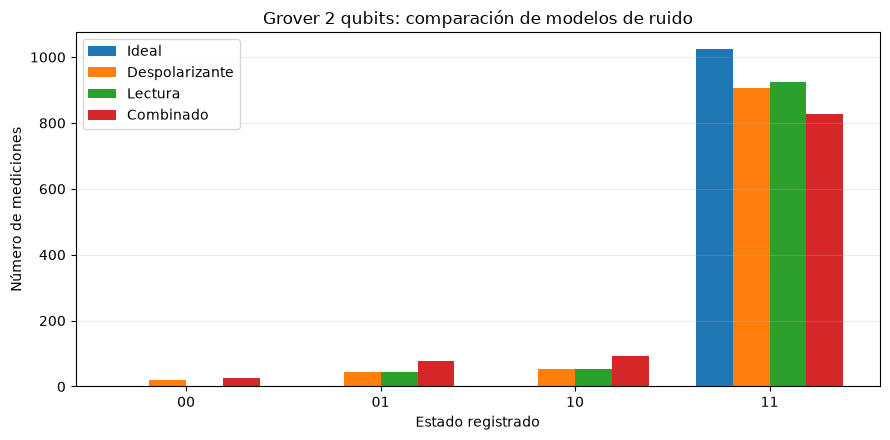

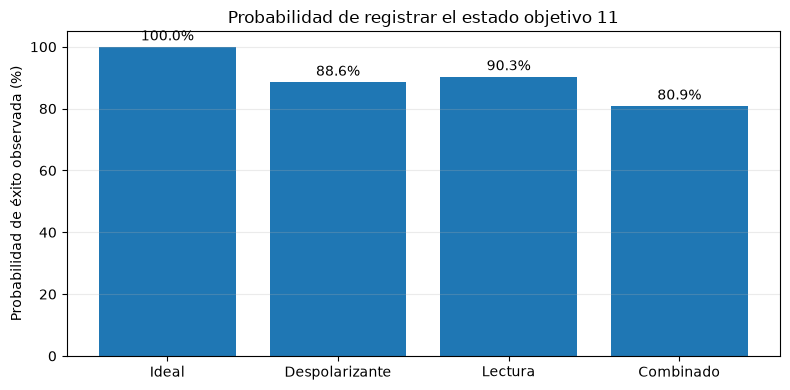

In [6]:
estados = ["00", "01", "10", "11"]
nombres = list(conteos)
posiciones = list(range(len(estados)))
ancho = 0.19

fig, ax = plt.subplots(figsize=(9, 4.5))
for i, nombre in enumerate(nombres):
    ax.bar(
        [x + (i - 1.5) * ancho for x in posiciones],
        [conteos[nombre].get(estado, 0) for estado in estados],
        width=ancho,
        label=nombre,
    )
ax.set_xticks(posiciones, estados)
ax.set_xlabel("Estado registrado")
ax.set_ylabel("Número de mediciones")
ax.set_title("Grover 2 qubits: comparación de modelos de ruido")
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(nombres, [100 * probabilidades[n] for n in nombres])
ax.set_ylabel("Probabilidad de éxito observada (%)")
ax.set_ylim(0, 105)
ax.set_title("Probabilidad de registrar el estado objetivo 11")
ax.grid(axis="y", alpha=0.25)
for i, nombre in enumerate(nombres):
    valor = 100 * probabilidades[nombre]
    ax.text(i, valor + 1, f"{valor:.1f}%", ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 7. Interpretación y conclusión

- **Ideal:** el circuito encuentra `11` con probabilidad del 100 %.
- **Despolarizante:** los errores en H, X y CZ degradan la preparación del estado.
- **Lectura:** el estado preparado puede ser correcto, pero los bits registrados pueden invertirse.
- **Combinado:** intervienen ambas fuentes de error; su efecto no se obtiene sumando porcentajes.

**Alcance:** esta prueba compara cuatro condiciones sobre **un mismo circuito de 2 qubits y una iteración**. No demuestra todavía cómo cambia el número óptimo de iteraciones. Para ello harán falta circuitos mayores y experimentos sistemáticos.

### Conclusiones

Se ha evaluado el algoritmo de Grover de dos qubits bajo cuatro condiciones: ejecución ideal, ruido despolarizante, errores de lectura y combinación de ambos modelos.

La simulación ideal alcanza una probabilidad de éxito del 100 %, mientras que las ejecuciones con ruido presentan probabilidades aproximadas del 88,6 % para la despolarización, 90,3 % para los errores de lectura y 80,9 % para el modelo combinado.

Los resultados muestran que la despolarización afecta a la evolución del circuito cuántico, mientras que los errores de lectura modifican los resultados registrados durante la medición. Su combinación produce una disminución adicional de la probabilidad de éxito, sin que los efectos puedan calcularse mediante una simple suma de porcentajes de error.

Esta prueba permite comprobar el funcionamiento conjunto de ambos modelos y constituye una base para posteriores experimentos con diferentes intensidades de ruido, tamaños de búsqueda y números de iteraciones.

**Referencias técnicas:** [NoiseModel](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.NoiseModel.html) · [depolarizing_error](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.depolarizing_error.html) · [ReadoutError](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.ReadoutError.html).